# Proyecto I – Preparación del dataset y EDA inicial
## 1. Introducción

**Problema:** en Colombia una parte importante de los ocupados no cotiza a pensión, y eso deja a muchas personas sin protección en la vejez.

**Pregunta del proyecto:** ¿qué probabilidad tiene un trabajador colombiano de cotizar a pensión, según su perfil personal, laboral y de hogar?

**Variable objetivo:** `cotiza_pension` (P6920 en la GEIH): 1 = cotiza, 0 = no cotiza. Los ya pensionados (código 3) se excluyen.

**Para qué sirve:** fondos de pensiones, Colpensiones, UGPP y política pública. También permite medir cuántos trabajadores ganan 1 SMMLV o más y aun así no cotizan.

**Fuente:** Gran Encuesta Integrada de Hogares (GEIH) 2025, DANE, módulo de ocupados.

**Alcance de esta fase:** solo preparación de datos y EDA. El modelado (regresión logística y boosting, con entrenamiento enero–septiembre y prueba octubre–diciembre) viene después.

## 2. Carga de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ruta = 'data/raw/geih_2025_ocupados_crudo.csv'
df = pd.read_csv(ruta)
df.shape

(358029, 26)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 358029 entries, 0 to 358028
Data columns (total 26 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   anio         358029 non-null  int64  
 1   mes          358029 non-null  int64  
 2   DIRECTORIO   358029 non-null  int64  
 3   SECUENCIA_P  358029 non-null  int64  
 4   ORDEN        358029 non-null  int64  
 5   HOGAR        358029 non-null  int64  
 6   MES          358029 non-null  int64  
 7   DPTO         358029 non-null  int64  
 8   CLASE        358029 non-null  int64  
 9   FEX_C18      358029 non-null  float64
 10  P6040        358029 non-null  int64  
 11  P3271        358029 non-null  int64  
 12  P6050        358029 non-null  int64  
 13  P6070        358029 non-null  float64
 14  P3042        358029 non-null  float64
 15  OCI          358029 non-null  float64
 16  P6920        358029 non-null  float64
 17  P6430        358029 non-null  float64
 18  P3069        358029 non-null  float

In [3]:
df.head()

,anio,mes,DIRECTORIO,SECUENCIA_P,ORDEN,HOGAR,MES,DPTO,CLASE,FEX_C18,...,P6920,P6430,P3069,P6880,P6800,P6426,P6440,INGLABO,RAMA2D_R4,P4030S1A1
0,2025,1,8086872,1,1,1,1,13,2,2184.752283,...,2.0,3.0,1.0,2.0,24.0,10.0,1.0,1040000.0,97.0,2.0
1,2025,1,8086874,1,2,1,1,13,2,1208.490211,...,2.0,4.0,1.0,8.0,60.0,480.0,2.0,700000.0,1.0,2.0
2,2025,1,8086874,1,3,1,1,13,2,1208.490211,...,2.0,1.0,2.0,8.0,50.0,12.0,1.0,1450000.0,1.0,2.0
3,2025,1,8086876,1,2,1,1,13,2,2420.064922,...,2.0,4.0,1.0,1.0,40.0,216.0,2.0,350000.0,47.0,2.0
4,2025,1,8086876,1,3,1,1,13,2,2420.064922,...,2.0,7.0,2.0,8.0,50.0,144.0,1.0,1350000.0,1.0,2.0


## 3. Diccionario de datos

Columna nueva, código original del DANE, descripción y si entra al modelo.

| Columna nueva | Código DANE | Descripción | ¿Entra al modelo? |
|---|---|---|---|
| anio | anio | Año de la encuesta (2025) | No (constante) |
| mes | mes / MES | Mes de la encuesta | No como variable; se usa para el split temporal |
| directorio | DIRECTORIO | Identificador de la vivienda | No (identificador) |
| secuencia_p | SECUENCIA_P | Identificador de la secuencia | No (identificador) |
| orden | ORDEN | Número de la persona en el hogar | No (identificador) |
| hogar | HOGAR | Número del hogar en la vivienda | No (identificador) |
| departamento | DPTO | Departamento | Sí |
| zona | CLASE | Cabecera (urbano) o resto (rural) | Sí |
| factor_expansion | FEX_C18 | Factor de expansión de la encuesta | No (se usa para estimar totales) |
| edad | P6040 | Edad en años | Sí |
| sexo | P3271 | Sexo | Sí |
| parentesco_jefe | P6050 | Parentesco con el jefe(a) del hogar | Sí |
| estado_civil | P6070 | Estado civil | Sí |
| nivel_educativo | P3042 | Nivel educativo más alto alcanzado | Sí |
| (se elimina) | OCI | Ocupado (siempre 1 en este archivo) | No (constante) |
| cotiza_pension | P6920 | ¿Cotiza a un fondo de pensiones? | Variable objetivo |
| posicion_ocupacional | P6430 | Posición ocupacional en el trabajo | Sí |
| tamano_empresa | P3069 | Cantidad de personas en la empresa o negocio | Sí |
| lugar_trabajo | P6880 | Lugar donde realiza el trabajo (código) | Sí |
| horas_semana | P6800 | Horas trabajadas a la semana | Sí |
| meses_en_empresa | P6426 | Meses trabajando en la empresa o negocio | Sí |
| tiene_contrato | P6440 | ¿Tiene contrato? (1 = sí, 0 = no) | Se prueba con y sin ella |
| ingreso | INGLABO | Ingreso laboral mensual (pesos) | No directo; se usa `ingreso_smmlv` |
| ingreso_smmlv | (calculada) | Ingreso dividido por el SMMLV 2025 | Sí |
| gana_1_smmlv_o_mas | (calculada) | 1 si ingreso ≥ 1 SMMLV, 0 si no | Para análisis; el modelo usa `ingreso_smmlv` |
| rama_2d | RAMA2D_R4 | Rama de actividad (CIIU Rev. 4, 2 dígitos) | Sí |
| estrato | P4030S1A1 | Estrato de la vivienda (energía eléctrica) | Sí |

**Origen del diccionario.** El archivo crudo solo trae códigos (P6800, P3042, etc.), sin descripciones, y los metadatos que vienen con los datos descargados (`metadata/2025.json`) solo describen la encuesta en general, no cada variable. Por eso los nombres y las categorías de la tabla salen del cuestionario y los diccionarios de la GEIH del DANE, tal como los conozco, y **no de un archivo incluido en el proyecto**. Para no depender solo de eso, se contrastaron con los datos:

- **Confirmadas con los datos:** `estado_civil` (edad promedio de cada código: unión libre reciente 31 años, viudo(a) 60), `posicion_ocupacional` (los familiares sin remuneración, código 6, no tienen ingreso; los empleados de empresa y del gobierno tienen contrato), `tamano_empresa` (el código 1 son casi todos cuenta propia y la cotización sube con cada código), `nivel_educativo` (la cotización sube con el nivel), `departamento`, `zona`, `sexo`, `edad`, `horas_semana` (mediana de 46 horas) e `ingreso` (el valor más repetido es 1.423.500, el SMMLV 2025).
- **Deducidas, por confirmar:** los códigos 9 y 10 de `tamano_empresa`, los códigos 7 y 8 de `posicion_ocupacional`, y el sentido de 1/2 en `tiene_contrato`.
- **Sin confirmar, por eso no se tradujeron:** `parentesco_jefe` (más allá de jefe, pareja e hijo), `lugar_trabajo` y los valores 0 y 9 de `estrato`.

Antes de entregar el proyecto conviene revisar estos puntos contra el diccionario oficial de la GEIH 2025 en la página del DANE.

## 4. Limpieza

Primero se eliminan `MES` (idéntica a `mes`, solo cambia la mayúscula) y `OCI` (todos son ocupados). Luego se pasan los nombres a minúscula con nombres claros.

In [4]:
print((df['mes'] != df['MES']).sum())
print(df['OCI'].unique())

0
[1.]


In [5]:
df = df.drop(columns=['MES', 'OCI'])
df.columns = df.columns.str.lower()

df = df.rename(columns={
    'dpto': 'departamento',
    'clase': 'zona',
    'fex_c18': 'factor_expansion',
    'p6040': 'edad',
    'p3271': 'sexo',
    'p6050': 'parentesco_jefe',
    'p6070': 'estado_civil',
    'p3042': 'nivel_educativo',
    'p6920': 'cotiza_pension',
    'p6430': 'posicion_ocupacional',
    'p3069': 'tamano_empresa',
    'p6880': 'lugar_trabajo',
    'p6800': 'horas_semana',
    'p6426': 'meses_en_empresa',
    'p6440': 'tiene_contrato',
    'inglabo': 'ingreso',
    'rama2d_r4': 'rama_2d',
    'p4030s1a1': 'estrato',
})
df.columns.tolist()

['anio',
 'mes',
 'directorio',
 'secuencia_p',
 'orden',
 'hogar',
 'departamento',
 'zona',
 'factor_expansion',
 'edad',
 'sexo',
 'parentesco_jefe',
 'estado_civil',
 'nivel_educativo',
 'cotiza_pension',
 'posicion_ocupacional',
 'tamano_empresa',
 'lugar_trabajo',
 'horas_semana',
 'meses_en_empresa',
 'tiene_contrato',
 'ingreso',
 'rama_2d',
 'estrato']

**Números.** Se verifica el tipo de las columnas numéricas. El factor de expansión ya se leyó como número con punto decimal (no tiene comas); se deja como `float`.

In [6]:
columnas_numericas = ['factor_expansion', 'ingreso', 'edad', 'horas_semana', 'meses_en_empresa']
print(df[columnas_numericas].dtypes)

df[columnas_numericas].describe()

factor_expansion    float64
ingreso             float64
edad                  int64
horas_semana        float64
meses_en_empresa    float64
dtype: object


,factor_expansion,ingreso,edad,horas_semana,meses_en_empresa
count,358029.000000,3.498300e+05,358029.000000,358029.000000,358029.000000
mean,798.620241,1.764269e+06,41.890408,43.581478,84.601178
std,1131.154344,2.232395e+06,14.180345,12.981913,111.223761
min,6.703899,0.000000e+00,15.000000,1.000000,0.000000
25%,161.529877,8.000000e+05,30.000000,40.000000,12.000000
50%,328.868619,1.423500e+06,41.000000,46.000000,36.000000
75%,961.490374,1.900000e+06,52.000000,48.000000,120.000000
max,17668.825277,1.030000e+08,100.000000,130.000000,950.000000


**Pensionados y variable objetivo.** En P6920: 1 = sí cotiza, 2 = no cotiza, 3 = ya pensionado. Se quitan los pensionados y se deja 1/0.

In [7]:
print(df['cotiza_pension'].value_counts())

df = df[df['cotiza_pension'] != 3].copy()
df['cotiza_pension'] = df['cotiza_pension'].map({1: 1, 2: 0})

df['cotiza_pension'].value_counts()

cotiza_pension
2.0    200796
1.0    150925
3.0      6308
Name: count, dtype: int64


cotiza_pension
0    200796
1    150925
Name: count, dtype: int64

**Códigos a palabras.** Se usan los códigos de la GEIH. Algunas categorías se confirmaron con los datos (por ejemplo, la edad promedio de cada estado civil y los ingresos de cada posición ocupacional). Los códigos que no se pudieron confirmar se dejaron agrupados o sin cambiar, y se avisa en las conclusiones.

In [8]:
df['sexo'] = df['sexo'].map({1: 'Hombre', 2: 'Mujer'})

df['zona'] = df['zona'].map({1: 'Urbano', 2: 'Rural'})

df['estado_civil'] = df['estado_civil'].map({
    1: 'Unión libre menos de 2 años',
    2: 'Unión libre 2 años o más',
    3: 'Casado(a)',
    4: 'Separado(a) o divorciado(a)',
    5: 'Viudo(a)',
    6: 'Soltero(a)',
})

df['nivel_educativo'] = df['nivel_educativo'].map({
    1: 'Ninguno',
    2: 'Preescolar',
    3: 'Básica primaria',
    4: 'Básica secundaria',
    5: 'Media académica',
    6: 'Media técnica',
    7: 'Normalista',
    8: 'Técnica profesional',
    9: 'Tecnológica',
    10: 'Universitaria',
    11: 'Especialización',
    12: 'Maestría',
    13: 'Doctorado',
    99: 'No sabe',
})

df['posicion_ocupacional'] = df['posicion_ocupacional'].map({
    1: 'Empleado empresa particular',
    2: 'Empleado del gobierno',
    3: 'Empleado doméstico',
    4: 'Cuenta propia',
    5: 'Patrón o empleador',
    6: 'Familiar sin remuneración',
    7: 'Jornalero o peón',
    8: 'Otro',
})

df['tamano_empresa'] = df['tamano_empresa'].map({
    1: 'Trabaja solo',
    2: '2 a 3',
    3: '4 a 5',
    4: '6 a 10',
    5: '11 a 19',
    6: '20 a 30',
    7: '31 a 50',
    8: '51 a 100',
    9: '101 a 200',
    10: '201 o más',
})

df['parentesco_jefe'] = df['parentesco_jefe'].map({
    1: 'Jefe(a) del hogar',
    2: 'Pareja del jefe(a)',
    3: 'Hijo(a)',
}).fillna('Otro')

df['tiene_contrato'] = df['tiene_contrato'].map({1: 1, 2: 0})

df['departamento'] = df['departamento'].map({
    5: 'Antioquia', 8: 'Atlántico', 11: 'Bogotá D.C.', 13: 'Bolívar', 15: 'Boyacá',
    17: 'Caldas', 18: 'Caquetá', 19: 'Cauca', 20: 'Cesar', 23: 'Córdoba',
    25: 'Cundinamarca', 27: 'Chocó', 41: 'Huila', 44: 'La Guajira', 47: 'Magdalena',
    50: 'Meta', 52: 'Nariño', 54: 'Norte de Santander', 63: 'Quindío', 66: 'Risaralda',
    68: 'Santander', 70: 'Sucre', 73: 'Tolima', 76: 'Valle del Cauca', 81: 'Arauca',
    85: 'Casanare', 86: 'Putumayo', 88: 'San Andrés', 91: 'Amazonas', 94: 'Guainía',
    95: 'Guaviare', 97: 'Vaupés', 99: 'Vichada',
})

df[['sexo', 'zona', 'estado_civil', 'nivel_educativo', 'posicion_ocupacional',
    'tamano_empresa', 'parentesco_jefe', 'tiene_contrato', 'departamento']].isna().sum()

sexo                    0
zona                    0
estado_civil            0
nivel_educativo         0
posicion_ocupacional    0
tamano_empresa          0
parentesco_jefe         0
tiene_contrato          0
departamento            0
dtype: int64

Si algún valor no estaba en el diccionario, aparecería arriba como nulo. Todos los conteos deben ser cero.

**Ingreso en SMMLV.** El salario mínimo mensual de 2025 es de $1.423.500 (también es el valor más repetido en `ingreso`). Si el ingreso es nulo, `gana_1_smmlv_o_mas` también queda nulo.

In [9]:
smmlv = 1423500

df['ingreso_smmlv'] = df['ingreso'] / smmlv
df['gana_1_smmlv_o_mas'] = (df['ingreso_smmlv'] >= 1).astype(float)
df.loc[df['ingreso'].isna(), 'gana_1_smmlv_o_mas'] = None

df[['ingreso', 'ingreso_smmlv', 'gana_1_smmlv_o_mas']].describe()

,ingreso,ingreso_smmlv,gana_1_smmlv_o_mas
count,3.438050e+05,343805.000000,343805.000000
mean,1.747716e+06,1.227760,0.516636
std,2.174840e+06,1.527812,0.499724
min,0.000000e+00,0.000000,0.000000
25%,8.000000e+05,0.561995,0.000000
50%,1.423500e+06,1.000000,1.000000
75%,1.900000e+06,1.334738,1.000000
max,1.030000e+08,72.356867,1.000000


In [10]:
print(df.shape)
df.head()

(351721, 26)


,anio,mes,directorio,secuencia_p,orden,hogar,departamento,zona,factor_expansion,edad,...,tamano_empresa,lugar_trabajo,horas_semana,meses_en_empresa,tiene_contrato,ingreso,rama_2d,estrato,ingreso_smmlv,gana_1_smmlv_o_mas
0,2025,1,8086872,1,1,1,Bolívar,Rural,2184.752283,54,...,Trabaja solo,2.0,24.0,10.0,1,1040000.0,97.0,2.0,0.730594,0.0
1,2025,1,8086874,1,2,1,Bolívar,Rural,1208.490211,60,...,Trabaja solo,8.0,60.0,480.0,0,700000.0,1.0,2.0,0.491746,0.0
2,2025,1,8086874,1,3,1,Bolívar,Rural,1208.490211,59,...,2 a 3,8.0,50.0,12.0,1,1450000.0,1.0,2.0,1.018616,1.0
3,2025,1,8086876,1,2,1,Bolívar,Rural,2420.064922,45,...,Trabaja solo,1.0,40.0,216.0,0,350000.0,47.0,2.0,0.245873,0.0
4,2025,1,8086876,1,3,1,Bolívar,Rural,2420.064922,44,...,2 a 3,8.0,50.0,144.0,1,1350000.0,1.0,2.0,0.948367,0.0


## 5. Variables excluidas por fuga de información

Hay variables de la GEIH que se contestan **solo si la persona ya cotiza**, o que son una consecuencia directa de cotizar. Si entraran al modelo, este "vería" la respuesta y las predicciones serían inútiles para el uso real. Por eso **no se usan**:

- **Fondo al que cotiza:** solo lo responde quien cotiza.
- **Quién paga el aporte:** igual, solo aplica a quien cotiza.
- **Régimen de salud contributivo:** en Colombia está atado a la relación laboral formal; quien cotiza a pensión casi siempre está en el contributivo.
- **ARL (riesgos laborales):** se afilia junto con salud y pensión.
- **Caja de compensación:** también viene con el empleo formal.
- **Informalidad del DANE:** se construye usando, entre otras cosas, si cotiza a pensión.

El archivo crudo que se recibió ya no trae estas columnas, así que no hay que quitarlas.

**`tiene_contrato`** se deja en el dataset, pero no se descarta ni se asume buena: es muy informativa y puede estar muy ligada a la formalidad. En el modelado se probará **con y sin** esta variable para ver cuánto cambia el resultado.

## 6. Variable objetivo

In [11]:
conteo = df['cotiza_pension'].value_counts()
porcentaje = df['cotiza_pension'].value_counts(normalize=True) * 100
print(conteo)
print(porcentaje.round(1))

peso = (df['cotiza_pension'] * df['factor_expansion']).sum() / df['factor_expansion'].sum() * 100
print('Con factor de expansión cotiza:', round(peso, 1), '%')

cotiza_pension
0    200796
1    150925
Name: count, dtype: int64
cotiza_pension
0    57.1
1    42.9
Name: proportion, dtype: float64
Con factor de expansión cotiza: 44.0 %


Cotiza cerca del 43 % y no cotiza cerca del 57 %. Las clases **no están muy desbalanceadas** (hay bastantes casos de ambas), así que no hace falta remuestrear; para el modelado basta con medir con métricas como AUC, no solo exactitud.

## 7. EDA básico

**Nulos por columna.**

In [12]:
nulos = df.isna().mean() * 100
nulos = nulos[nulos > 0].sort_values()
print(nulos.round(2))

estrato               0.43
ingreso               2.25
ingreso_smmlv         2.25
gana_1_smmlv_o_mas    2.25
dtype: float64


Solo `ingreso` y `estrato` tienen nulos propios (2,25 % y 0,43 %). `ingreso_smmlv` y `gana_1_smmlv_o_mas` se calculan desde `ingreso`, por eso tienen exactamente los mismos nulos. Los nulos de ingreso son sobre todo familiares sin remuneración.

**% que cotiza por mes.**

In [13]:
por_mes = df.groupby('mes')['cotiza_pension'].mean() * 100
print(por_mes.round(1))

mes
1     42.5
2     42.1
3     42.1
4     43.3
5     42.9
6     43.7
7     43.1
8     43.4
9     43.6
10    42.8
11    42.8
12    42.5
Name: cotiza_pension, dtype: float64


La tasa se mantiene bastante estable durante el año, sin saltos fuertes entre los meses de entrenamiento (1–9) y de prueba (10–12).

**% que cotiza por edad.**

In [14]:
grupo_edad = pd.cut(df['edad'], bins=[14, 24, 34, 44, 54, 64, 120],
                    labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65+'])
por_edad = df.groupby(grupo_edad, observed=True)['cotiza_pension'].mean() * 100
print(por_edad.round(1))

edad
15-24    34.8
25-34    51.8
35-44    50.5
45-54    44.0
55-64    33.1
65+      10.2
Name: cotiza_pension, dtype: float64


La cotización sube hasta cerca de 52 % entre los 25 y 34 años, se mantiene en 50 % hasta los 44 y luego baja: 44 % a los 45–54, 33 % a los 55–64 y solo 10 % después de los 65.

**% que cotiza por sexo.**

In [15]:
por_sexo = df.groupby('sexo')['cotiza_pension'].mean() * 100
print(por_sexo.round(1))

sexo
Hombre    41.2
Mujer     45.1
Name: cotiza_pension, dtype: float64


Las mujeres cotizan un poco más que los hombres (45 % frente a 41 %), una diferencia pequeña comparada con la de otras variables.

**% que cotiza por nivel educativo.**

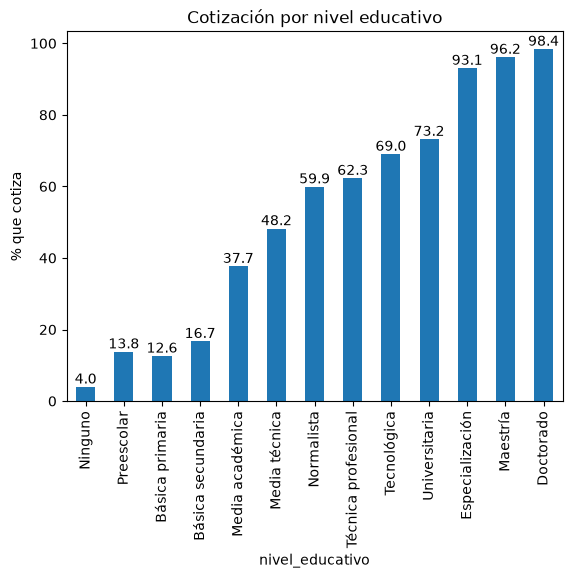

In [16]:
orden_edu = ['Ninguno', 'Preescolar', 'Básica primaria', 'Básica secundaria', 'Media académica',
             'Media técnica', 'Normalista', 'Técnica profesional', 'Tecnológica',
             'Universitaria', 'Especialización', 'Maestría', 'Doctorado']
por_edu = df.groupby('nivel_educativo')['cotiza_pension'].mean() * 100
por_edu = por_edu.reindex(orden_edu).dropna()
ax = por_edu.plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.ylabel('% que cotiza')
plt.title('Cotización por nivel educativo')
plt.xticks(rotation=90)
plt.show()

A mayor nivel educativo, mayor cotización: de 4 % sin estudios y 13 % con primaria a más de 93 % con posgrado.

**% que cotiza por posición ocupacional.**

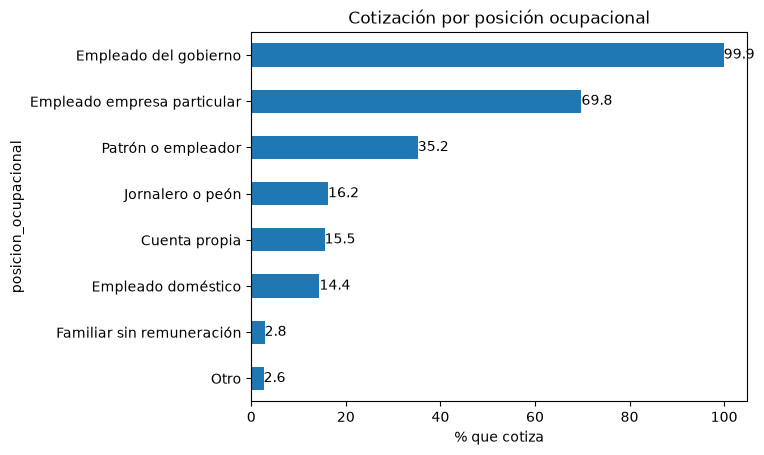

In [17]:
por_pos = df.groupby('posicion_ocupacional')['cotiza_pension'].mean() * 100
ax = por_pos.sort_values().plot(kind='barh')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.xlabel('% que cotiza')
plt.title('Cotización por posición ocupacional')
plt.show()

Casi todos los empleados del gobierno cotizan (más de 99 %) y 70 % de los de empresa particular; los patrones cotizan 35 % y cuenta propia, jornaleros, domésticos y familiares sin remuneración, menos de 17 %.

**% que cotiza por tamaño de empresa.**

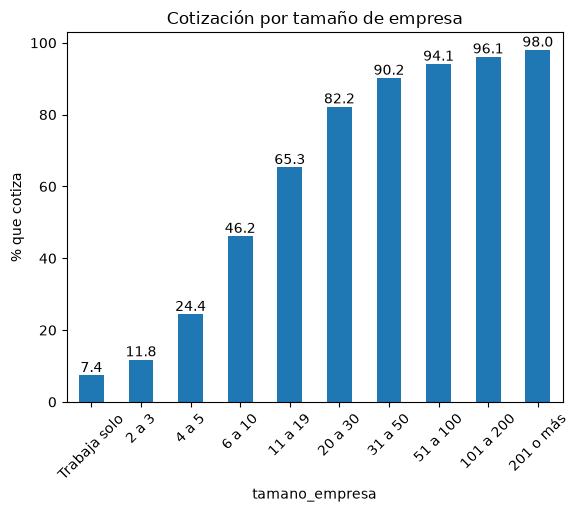

In [18]:
orden_tam = ['Trabaja solo', '2 a 3', '4 a 5', '6 a 10', '11 a 19', '20 a 30',
             '31 a 50', '51 a 100', '101 a 200', '201 o más']
por_tam = df.groupby('tamano_empresa')['cotiza_pension'].mean() * 100
por_tam = por_tam.reindex(orden_tam)
ax = por_tam.plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.ylabel('% que cotiza')
plt.title('Cotización por tamaño de empresa')
plt.xticks(rotation=45)
plt.show()

La cotización crece de forma casi continua con el tamaño: 7 % entre quienes trabajan solos, 46 % en empresas de 6 a 10 personas y más de 90 % en empresas de 31 personas o más.

**% que cotiza por ingreso (corte en 1 SMMLV).**

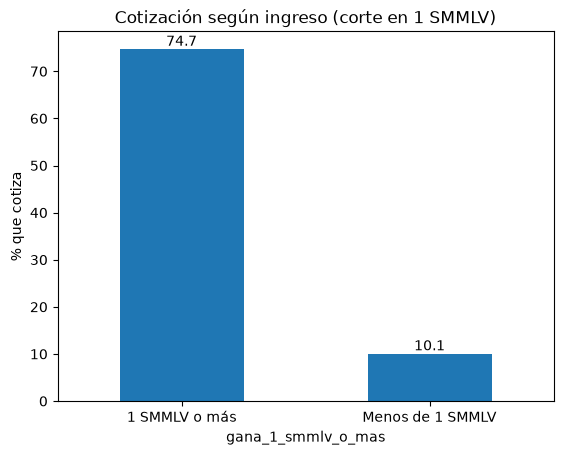

In [19]:
rango_ingreso = df['gana_1_smmlv_o_mas'].map({0.0: 'Menos de 1 SMMLV', 1.0: '1 SMMLV o más'})
por_ing = df.groupby(rango_ingreso)['cotiza_pension'].mean() * 100
ax = por_ing.plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.ylabel('% que cotiza')
plt.title('Cotización según ingreso (corte en 1 SMMLV)')
plt.xticks(rotation=0)
plt.show()

**% que cotiza por zona.**

In [21]:
por_zona = df.groupby('zona')['cotiza_pension'].mean() * 100
print(por_zona.round(1))

zona
Rural     18.5
Urbano    46.3
Name: cotiza_pension, dtype: float64


En la zona urbana cotiza 46 % y en la rural solo 18 %.

## 8. Conclusiones

1. **Casi 6 de cada 10 ocupados no cotiza a pensión** (57 % en la muestra; 56 % con factor de expansión); las clases no están muy desbalanceadas y la tasa es estable durante el año (42–44 % cada mes), lo que ayuda al split temporal.
2. **Las variables laborales pesan más que las personales:** posición ocupacional, tamaño de empresa y nivel educativo separan mucho más (de 4 % a más de 90 %) que el sexo (41 % frente a 45 %).
3. **El ingreso importa, pero no explica todo:** cerca de una cuarta parte de quienes ganan 1 SMMLV o más no cotiza, y ese grupo es el objetivo de política pública.
4. **La zona rural y el trabajo independiente o en empresas muy pequeñas concentran la baja cotización.**

**Avisos sobre los datos:**
- El factor de expansión no trae coma decimal en este archivo: ya viene con punto y como número.
- `parentesco_jefe` solo distingue jefe, pareja e hijo(a); los demás códigos se agruparon como "Otro" porque no se pudieron confirmar.
- `lugar_trabajo` y `estrato` se dejaron con su código original (en `estrato` hay valores 0 y 9 sin confirmar).
- En `tamano_empresa`, la separación de los códigos 9 (101 a 200) y 10 (201 o más) se dedujo del patrón de los datos, sin tabla oficial a la mano.
- En `posicion_ocupacional`, los códigos 7 (jornalero o peón) y 8 (otro) se dedujeron igual.

**Qué sigue:** split temporal (enero–septiembre entrenamiento, octubre–diciembre prueba), regresión logística y boosting, probando `tiene_contrato` con y sin ella.